# The ten most-cited architectures, drawn by Tensorgami

Do the figures in the most-cited deep-learning papers and Tensorgami's automatic drawings show the same thing? This notebook takes the ten most-cited deep-learning papers that contain a figure of their architecture, rebuilds each model in PyTorch as the paper describes it ([`classics.py`](classics.py); ResNet from [`resnet.py`](resnet.py)), and draws it with one `tg.draw` call next to the paper's own figure.

**How the papers were chosen.** Google Scholar citation counts, read on 14 October 2026 from the authors' profile pages. Counts differ between databases; [Nature's 2025 analysis](https://www.nature.com/articles/d41586-025-01125-9) of the most-cited papers of the century, across all fields and five databases, ranks ResNet 1st, the Transformer 7th, AlexNet 8th and U-Net 12th. Only papers with a figure of their model's architecture are kept. Left out, although cited more than the tenth: Adam (266,384; an optimiser), VGG (167,013; its architectures are given as a table), the review *Deep learning* (125,106; generic illustrations) and GAN (124,099; no architecture figure).

| # | Paper | Citations | Its figure |
|---|---|---:|---|
| 1 | He, Zhang, Ren & Sun, *Deep Residual Learning for Image Recognition*, CVPR 2016 (**ResNet**) | 350,942 | Fig. 2, Fig. 3 |
| 2 | Vaswani et al., *Attention Is All You Need*, NeurIPS 2017 (**Transformer**) | 290,743 | Fig. 1 |
| 3 | Krizhevsky, Sutskever & Hinton, *ImageNet Classification with Deep Convolutional Neural Networks*, NeurIPS 2012 (**AlexNet**) | 201,412 | Fig. 2 |
| 4 | Devlin, Chang, Lee & Toutanova, *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*, NAACL 2019 (**BERT**) | 185,877 | Fig. 1 |
| 5 | Hochreiter & Schmidhuber, *Long Short-Term Memory*, Neural Computation 1997 (**LSTM**) | 163,300 | Fig. 1 |
| 6 | Ronneberger, Fischer & Brox, *U-Net: Convolutional Networks for Biomedical Image Segmentation*, MICCAI 2015 (**U-Net**) | 152,520 | Fig. 1 |
| 7 | Ren, He, Girshick & Sun, *Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks*, NeurIPS 2015 (**Faster R-CNN**) | 111,801 | Fig. 2 |
| 8 | Dosovitskiy et al., *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale*, ICLR 2021 (**ViT**) | 110,951 | Fig. 1 |
| 9 | LeCun, Bottou, Bengio & Haffner, *Gradient-Based Learning Applied to Document Recognition*, Proc. IEEE 1998 (**LeNet-5**) | 91,030 | Fig. 2 |
| 10 | Redmon, Divvala, Girshick & Farhadi, *You Only Look Once: Unified, Real-Time Object Detection*, CVPR 2016 (**YOLO**) | 84,269 | Fig. 3 |

**The papers' figures** are shown from arXiv's HTML versions ([ar5iv](https://ar5iv.labs.arxiv.org)): linked, not copied into this notebook, so they need an internet connection, and they remain © their authors. AlexNet, LSTM and LeNet-5 are not on arXiv; their figures are linked by page in the papers' PDFs.

Each section: the paper's figure, Tensorgami's drawing, then what is the same, what Tensorgami adds and what differs.

In [1]:
import torch
from classics import (
    FASTER_RCNN_OVERRIDES,
    LENET_OVERRIDES,
    YOLO,
    AlexNet2012,
    Bert,
    FasterRCNN,
    LeNet5,
    LSTMNet,
    Transformer,
    UNet,
    VisionTransformer,
)
from resnet import BasicBlock, resnet34

import tensorgami as tg


def meta(model_class, **kwargs):
    """The model on PyTorch's meta device: shapes only, no weights in memory. A drawing
    needs no weights, so Tensorgami traces it as usual, even at hundreds of millions of
    parameters."""
    with torch.device("meta"):
        return model_class(**kwargs)

## 1. ResNet · He, Zhang, Ren & Sun (2016) · 350,942 citations

[arXiv:1512.03385](https://arxiv.org/abs/1512.03385). Left, Fig. 2: the residual building block. Right, Fig. 3: the 34-layer residual network next to VGG-19 and a plain 34-layer network (a tall figure: open it for the whole of it).

<img src="https://ar5iv.labs.arxiv.org/html/1512.03385/assets/block.svg" alt="ResNet, Fig. 2" width="320"> <img src="https://ar5iv.labs.arxiv.org/html/1512.03385/assets/arch.svg" alt="ResNet, Fig. 3" width="520">

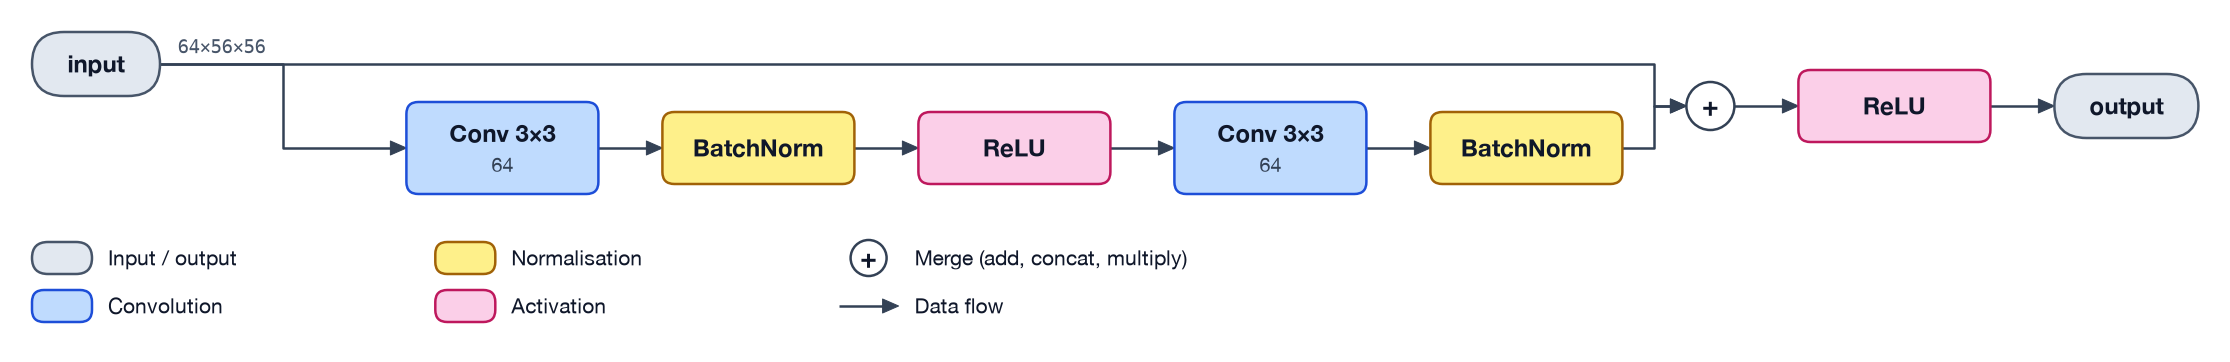

In [2]:
tg.draw(BasicBlock(64, 64), torch.randn(1, 64, 56, 56), level="operators", wrap_width=None)

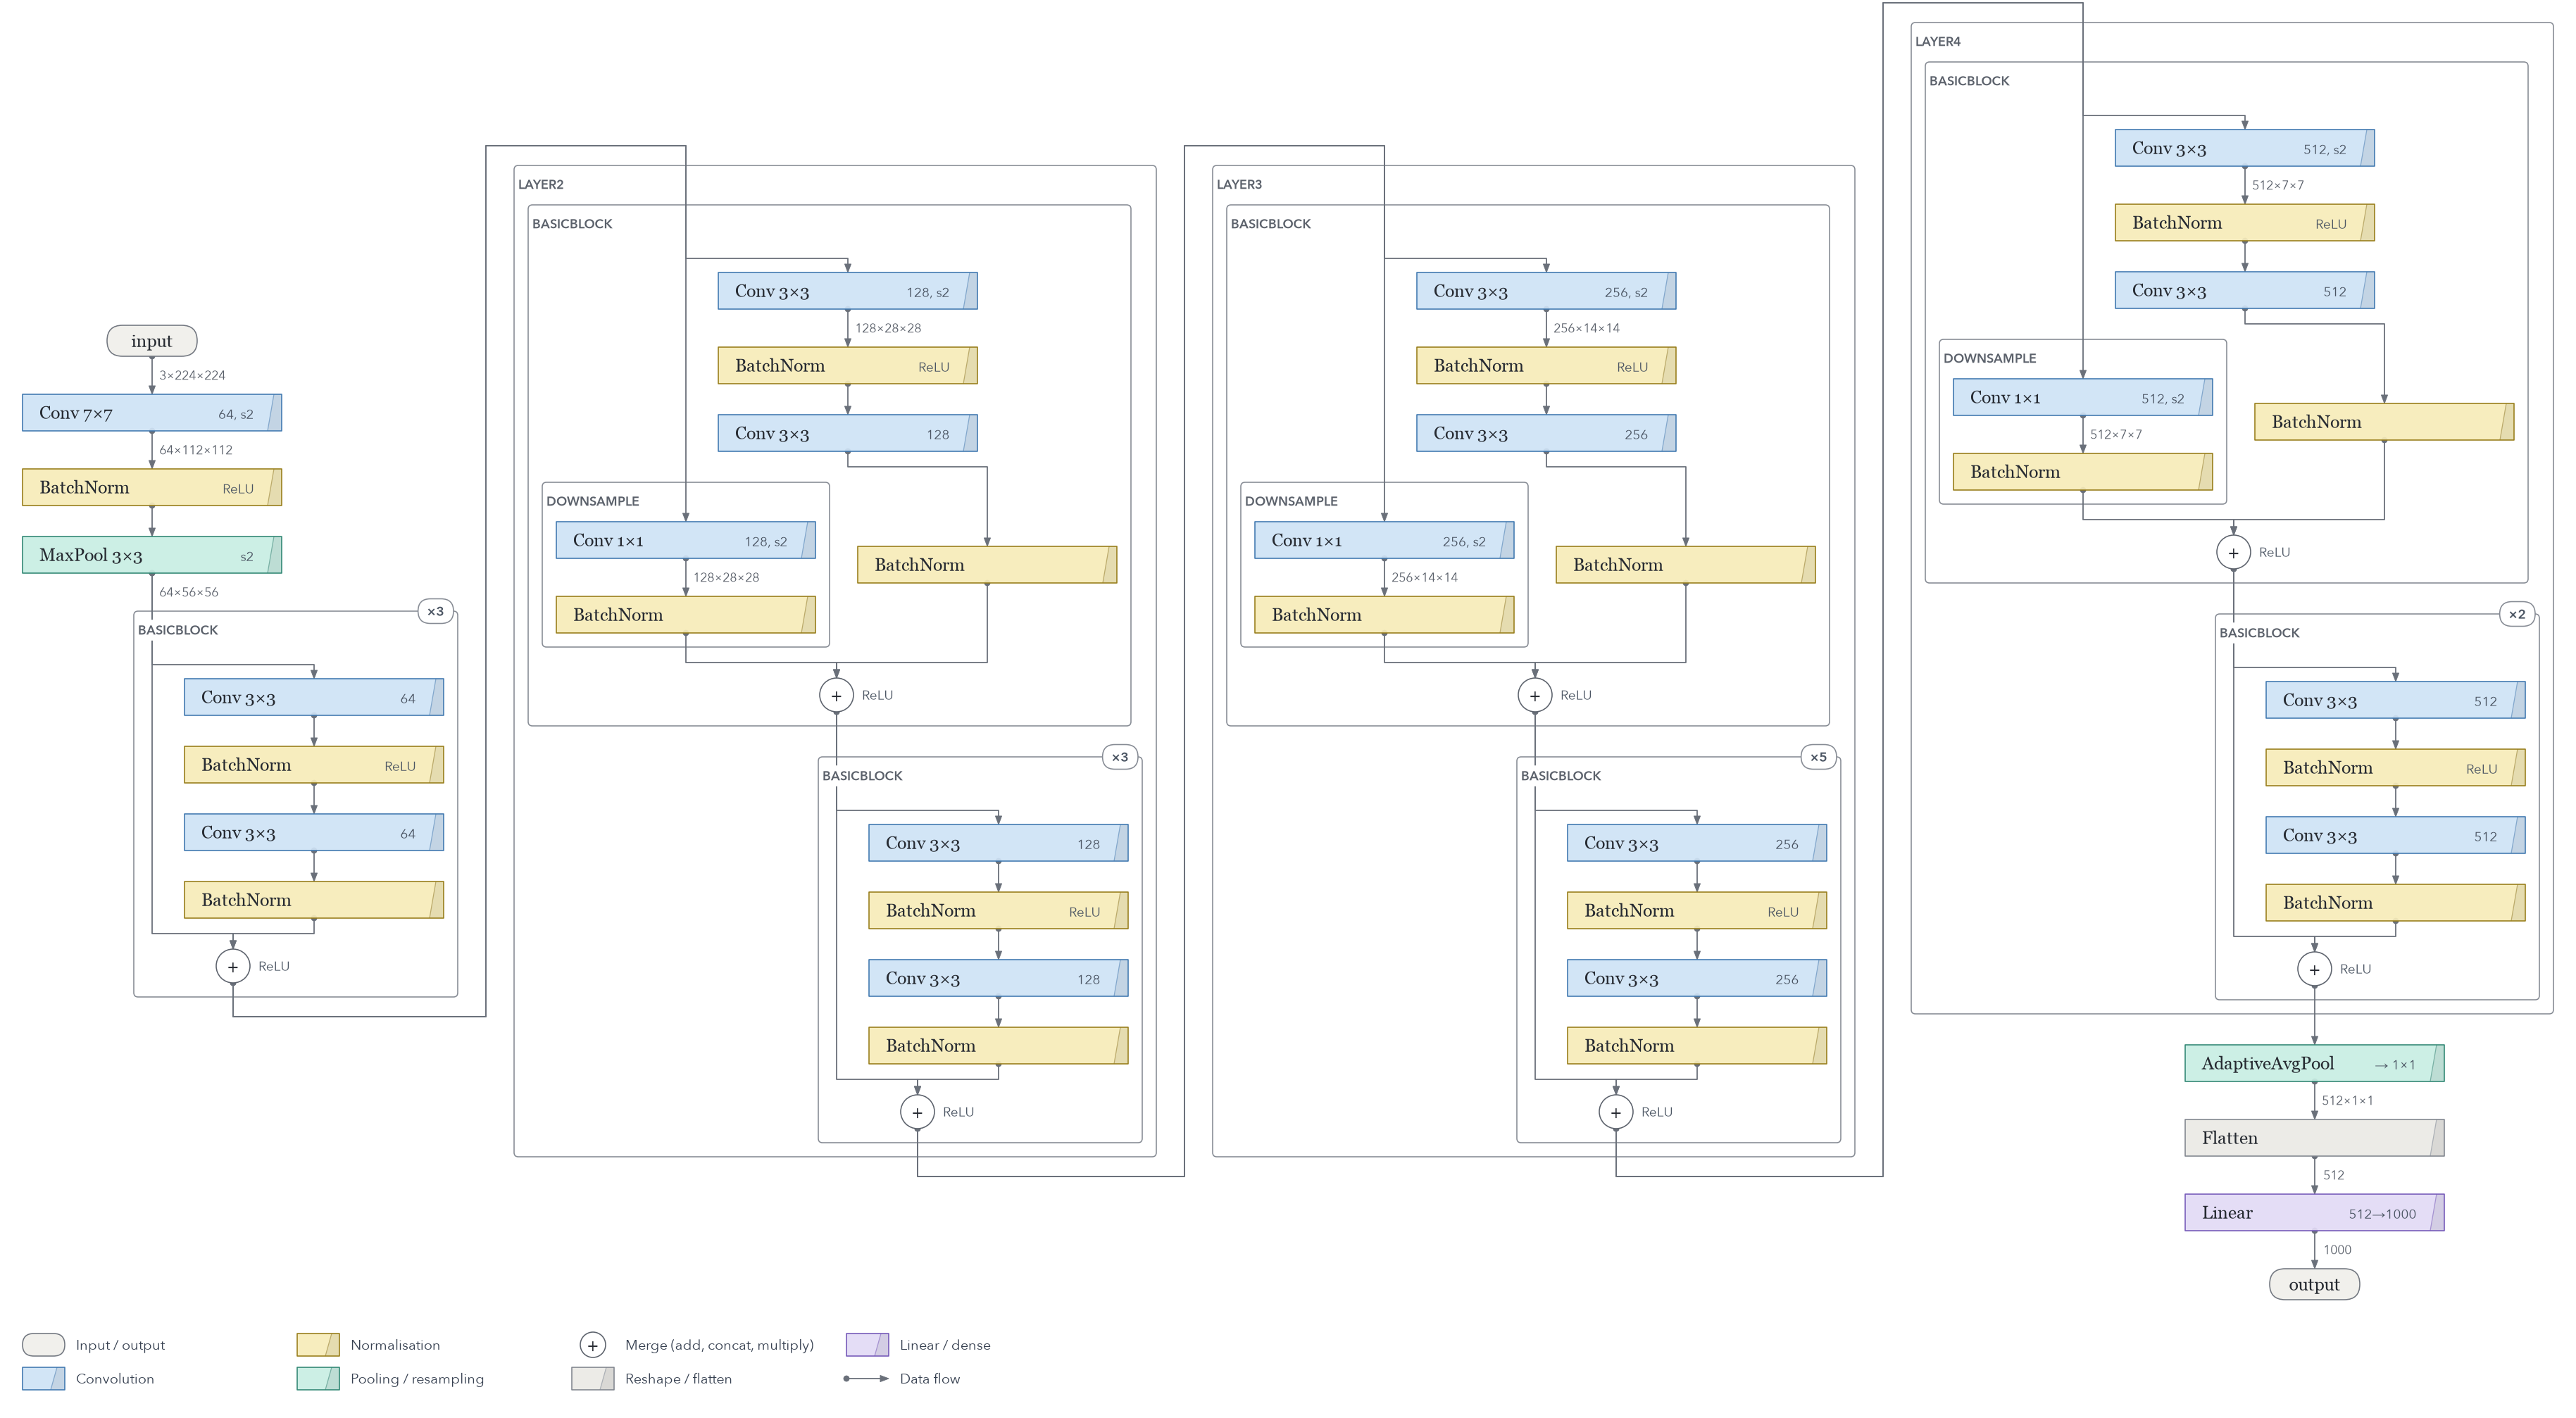

In [3]:
tg.draw(meta(resnet34), torch.randn(1, 3, 224, 224), style="origami-extended")

**The same:** the block's two 3×3 convolutions with a ReLU between them, the input added back (⊕) and the ReLU after the sum. In the network: the 7×7 convolution and pooling, four stages of 64, 128, 256 and 512 channels, each after the first halving the resolution (`/2` in the paper, `s2` here), then average pooling and the 1000-way classifier.

**Tensorgami adds:** batch normalisation after every convolution (in the paper's text, not its figures), and the tensor's shape wherever it changes, where the paper prints "output size" in the margin.

**Different:** the paper draws all 34 layers in one tall column, to make the depth visible; Tensorgami draws each run of identical blocks once and marks it ×3, ×5, ×2, and stands the network in four columns, one per stage, so it fits a page. The paper's dotted shortcuts, projections where the size changes, are the `downsample` frames here (a 1×1 convolution with stride 2), and its curved skips are straight wires.

## 2. Transformer · Vaswani et al. (2017) · 290,743 citations

[arXiv:1706.03762](https://arxiv.org/abs/1706.03762), Fig. 1: the model architecture.

<img src="https://ar5iv.labs.arxiv.org/html/1706.03762/assets/Figures/ModalNet-21.png" alt="Transformer, Fig. 1" width="380">

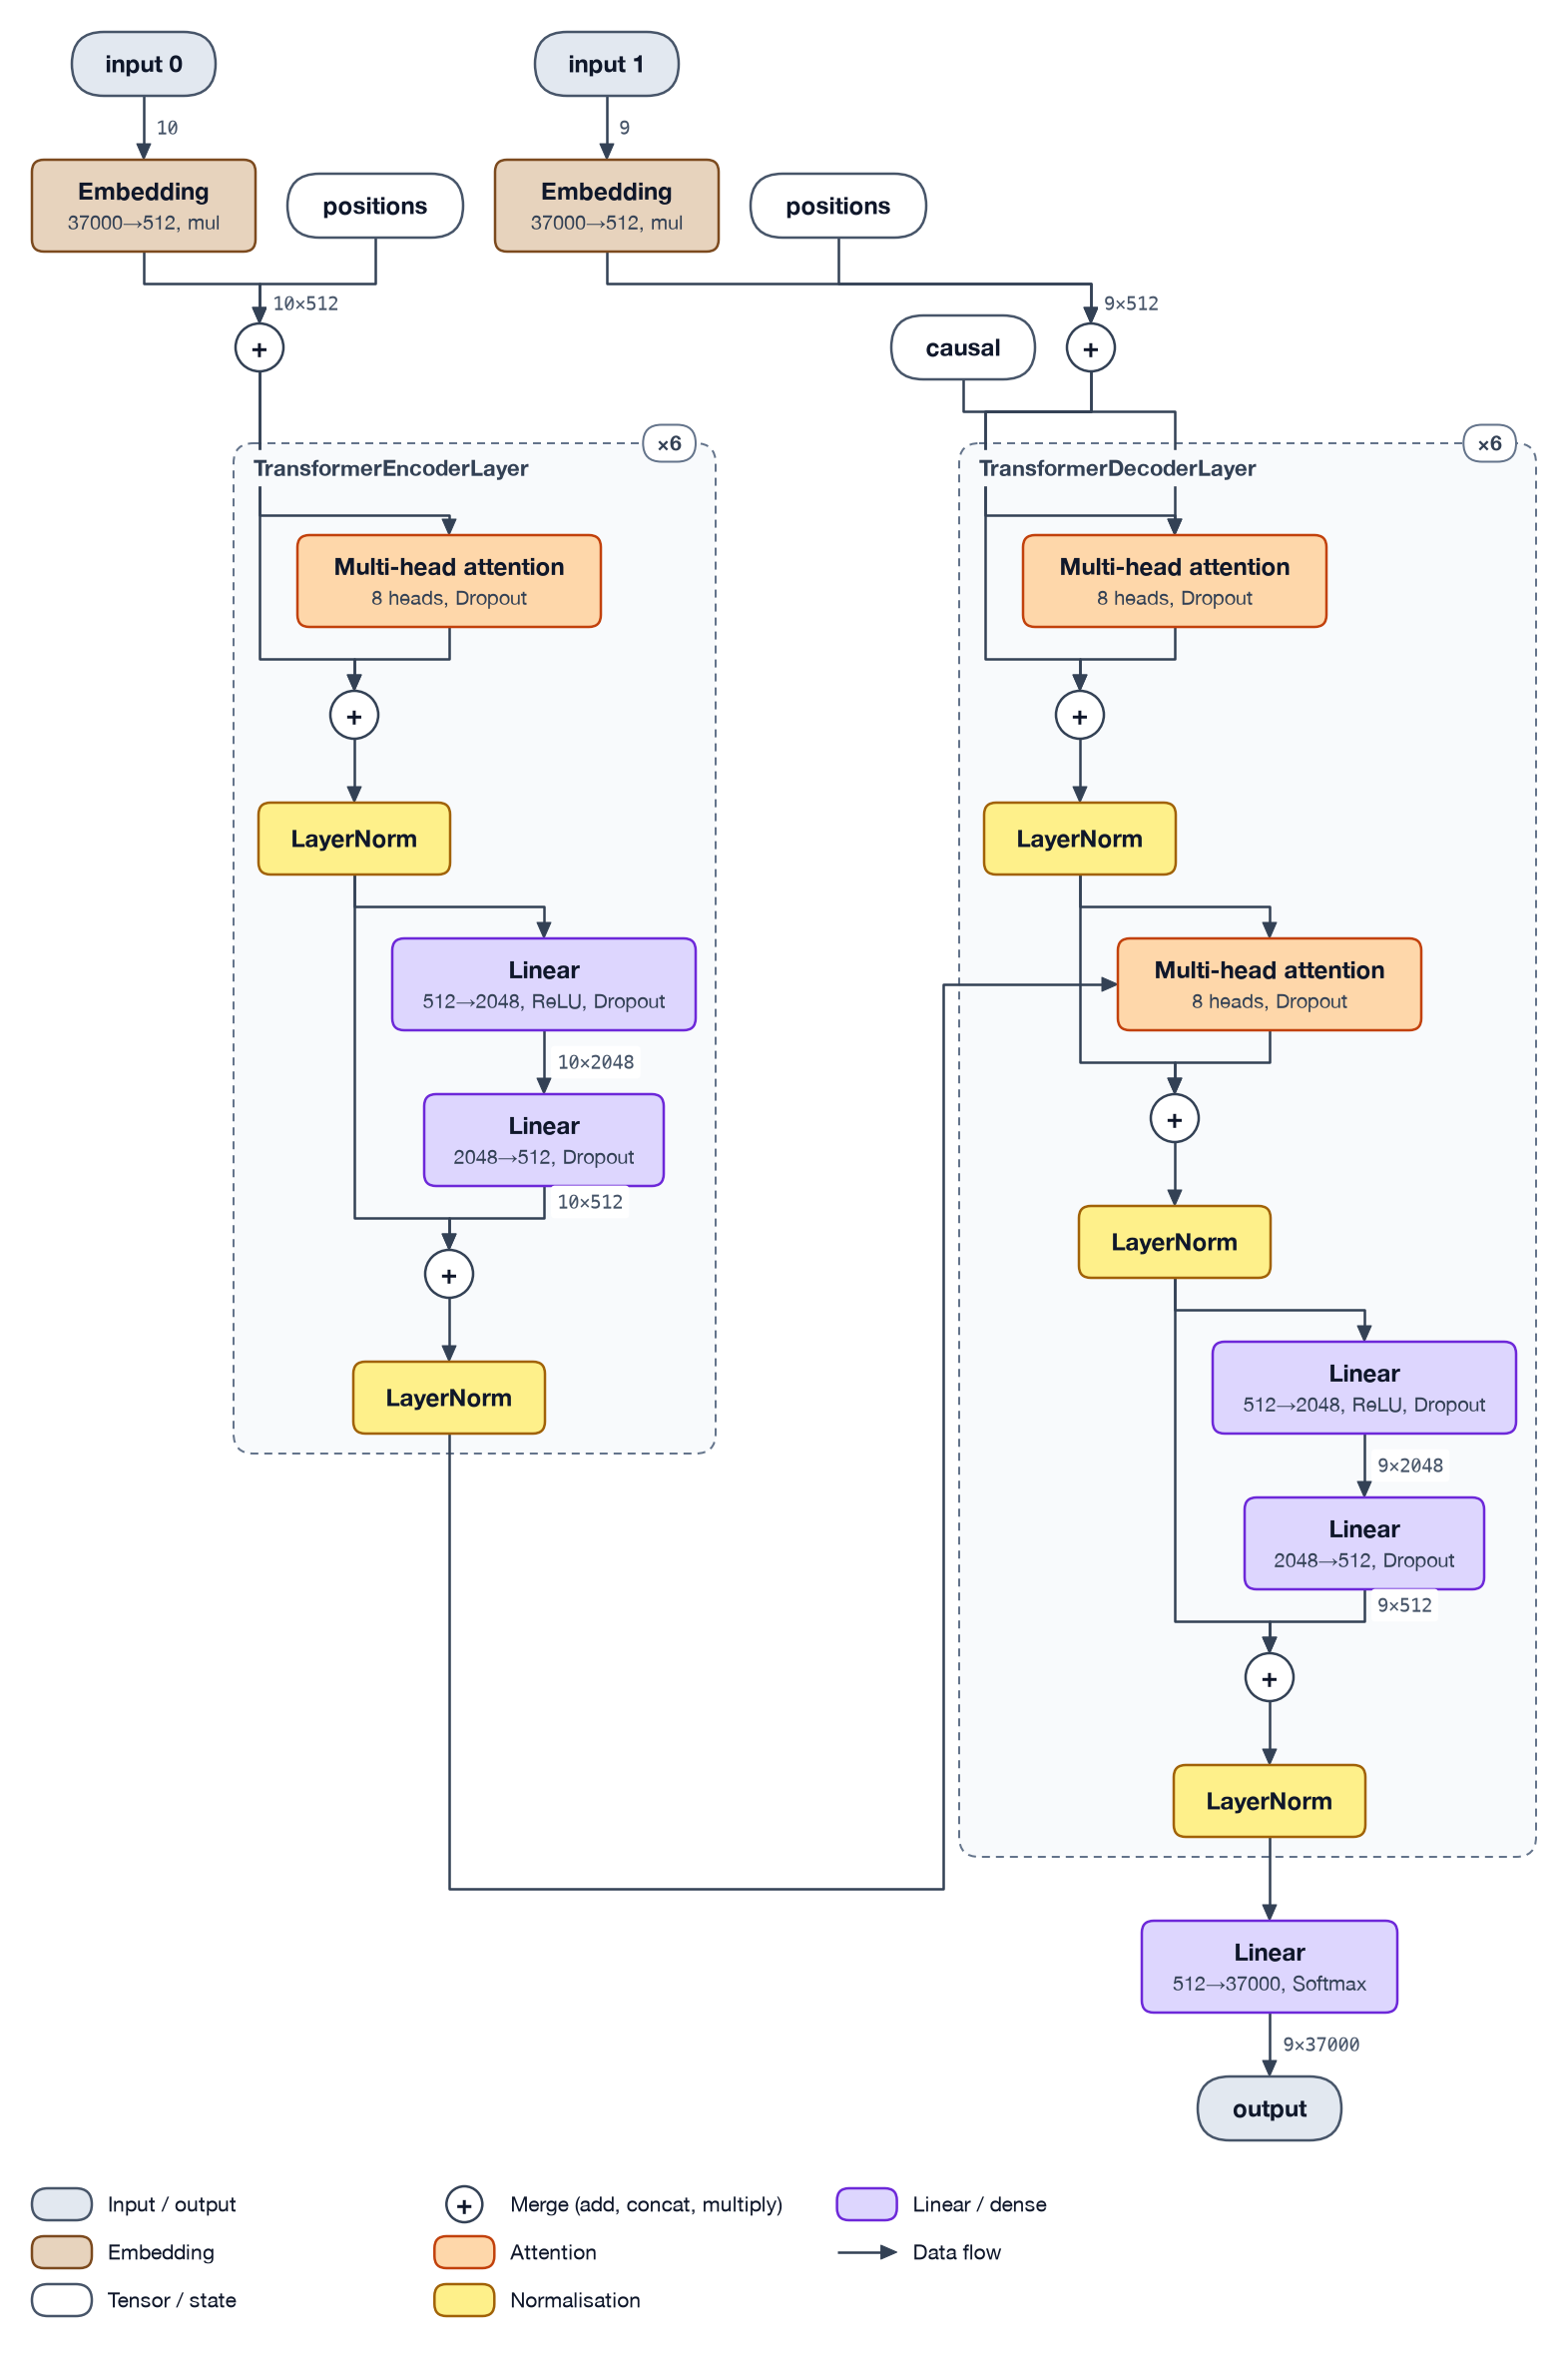

In [4]:
source, target = torch.randint(0, 37000, (1, 10)), torch.randint(0, 37000, (1, 9))
tg.draw(meta(Transformer), (source, target), direction="TB")

**The same:** the two stacks side by side, as in the paper: the encoder on the left, the decoder on the right, both starting at the same height; input and output embeddings with the positional encodings added (⊕); the encoder layer (multi-head attention, add & norm, feed-forward, add & norm) and the decoder layer, each repeated N = 6 times (×6), with the encoder's output crossing over into the decoder's second attention from the side; the final linear layer with softmax. "Add & Norm" is drawn as what it computes, the residual ⊕ and a LayerNorm, and "Feed Forward" as its two linear layers (512 → 2048 → 512).

**Tensorgami adds:** the shapes (10 × 512 …), the vocabulary of the embeddings and of the output (37,000), and that the embeddings are scaled (`mul`, by √512).

**Different:** the flow runs top → bottom where the paper's runs bottom → top. The decoder's first attention is not labelled *masked*: its mask enters as the tensor `causal`. The positional encodings are the tensor `positions`, not the paper's sine symbol.

## 3. AlexNet · Krizhevsky, Sutskever & Hinton (2012) · 201,412 citations

Not on arXiv: see [Fig. 2 on page 5 of the paper (PDF)](https://papers.nips.cc/paper_files/paper/2012/file/c399862d3b9d6b76c8436e924a68c45b-Paper.pdf#page=5), the network as volumes, split between two GPUs. This is the paper's AlexNet (96-256-384-384-256 kernels), not the later single-GPU variant in torchvision that `alexnet.ipynb` draws.

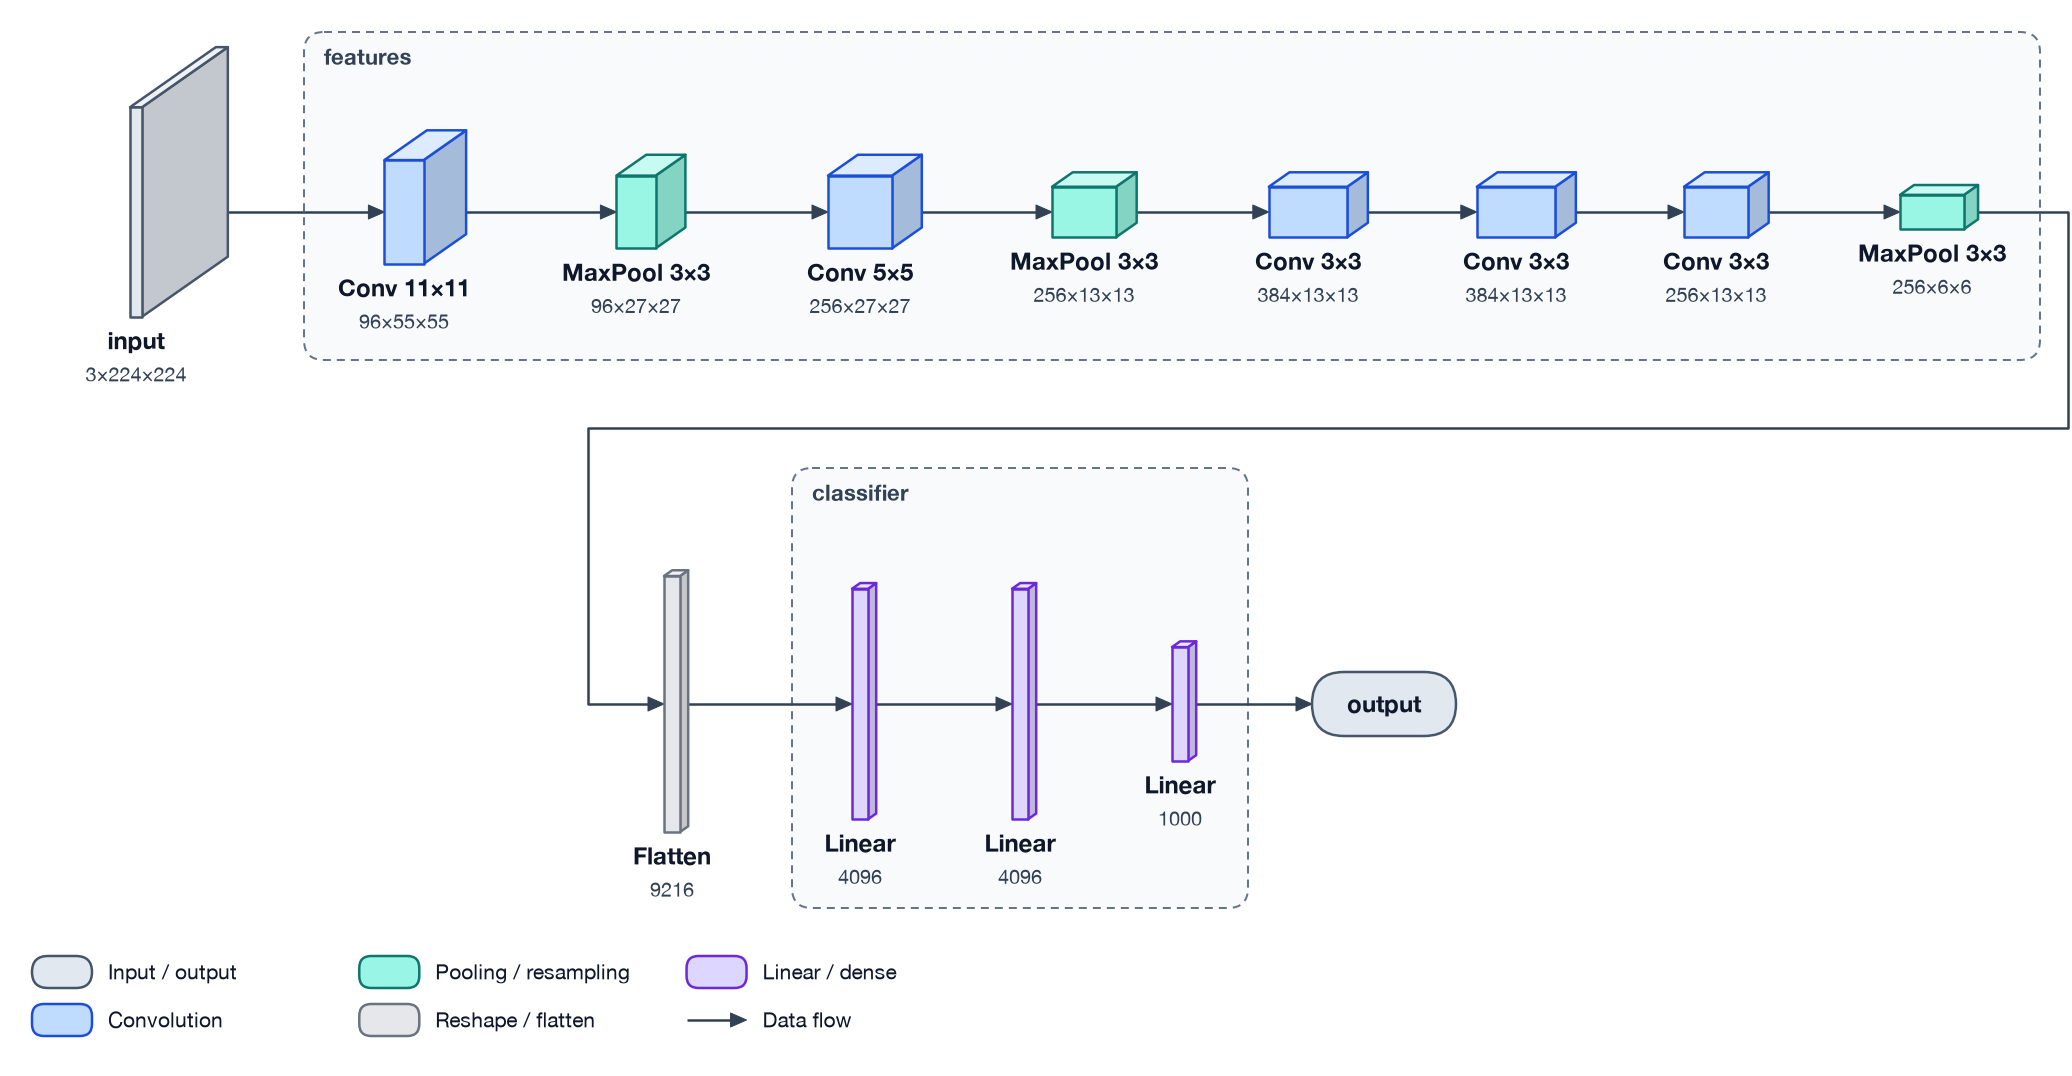

In [5]:
tg.draw(meta(AlexNet2012), torch.randn(1, 3, 224, 224), view="volume")

**The same:** the drawing the paper made famous: every layer as the tensor it produces, the five convolutional layers (96 × 55 × 55 … 256 × 13 × 13) with their max pooling, and the dense layers of 4096, 4096 and 1000, sizes below each.

**Different:** the paper draws each layer in two halves, one per GPU (48 + 48 kernels …), with lines crossing where the GPUs exchange data. The model here computes the same split (grouped convolutions, `groups=2`), but Tensorgami draws each layer whole. The paper's small cubes, the kernels' receptive fields, are not drawn, and the local response normalisation is folded into the layer before it.

## 4. BERT · Devlin, Chang, Lee & Toutanova (2019) · 185,877 citations

[arXiv:1810.04805](https://arxiv.org/abs/1810.04805), Fig. 1: pre-training (left) and fine-tuning (right).

<img src="https://ar5iv.labs.arxiv.org/html/1810.04805/assets/BERT_Overall.svg" alt="BERT, Fig. 1" width="720">

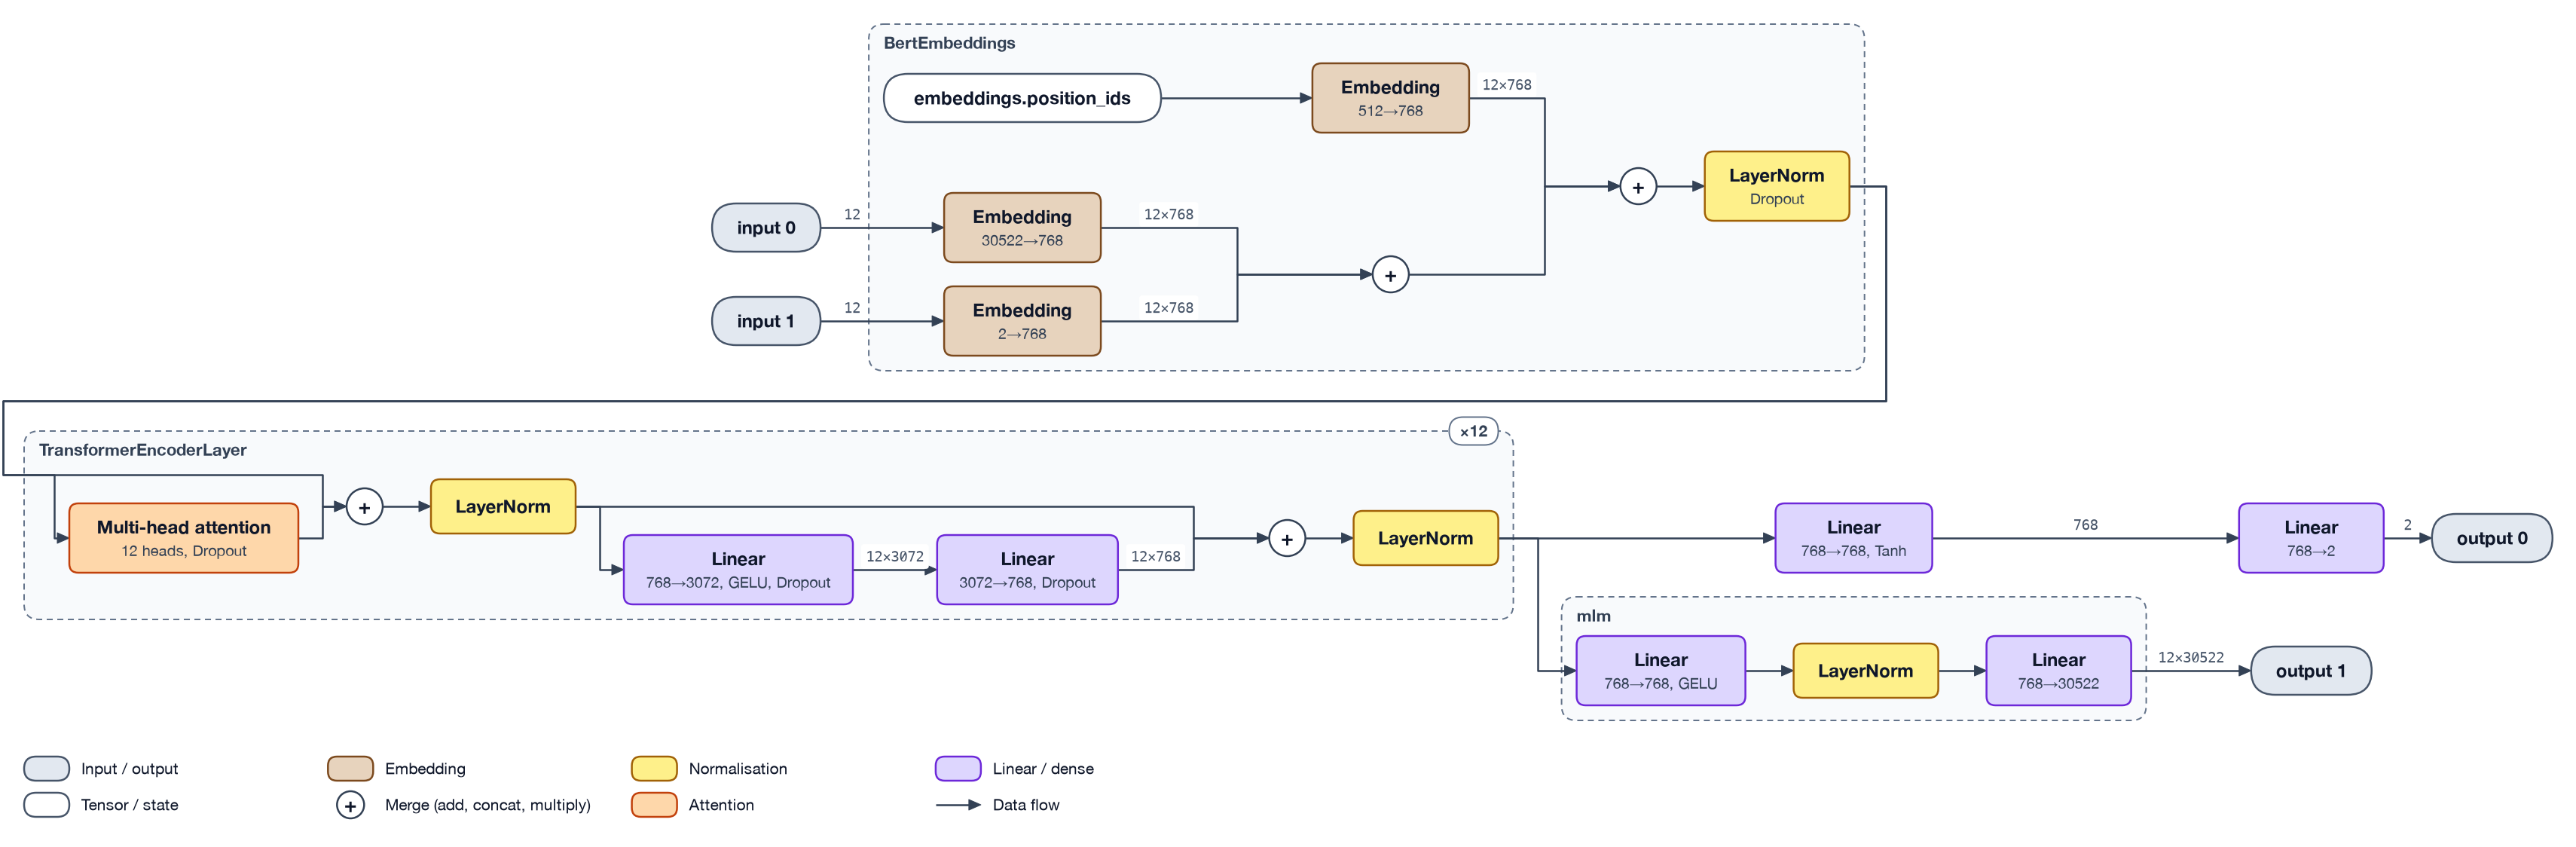

In [6]:
tokens, segments = torch.randint(0, 30522, (1, 12)), torch.zeros(1, 12, dtype=torch.long)
tg.draw(meta(Bert), (tokens, segments))

**The same:** the input embeddings, token, segment and position summed (the paper's Fig. 2; here `BertEmbeddings`); the stack of Transformer encoder layers (×12); the two pre-training outputs: C, the output at [CLS], into next-sentence prediction (`output 0`, 2 classes), and every token's output into the masked language model (`output 1`, a word per position).

**Tensorgami adds:** what the encoder box holds (attention, ⊕, LayerNorm, the 768 → 3072 → 768 feed-forward with GELU), where the paper's figure shows one box.

**Different:** the paper draws a column per token (E₁ … T_N), to show that every position sees every other; here the tokens are a dimension of the tensors (12 × 768). The fine-tuning half of the figure is a different model, with other heads: draw that model to see it.

## 5. LSTM · Hochreiter & Schmidhuber (1997) · 163,300 citations

Not on arXiv: see [Fig. 1 on page 7 of the paper (PDF)](https://www.bioinf.jku.at/publications/older/2604.pdf#page=7), the memory cell with its input and output gates and the *constant error carousel*, the cell's connection to itself with weight 1.0.

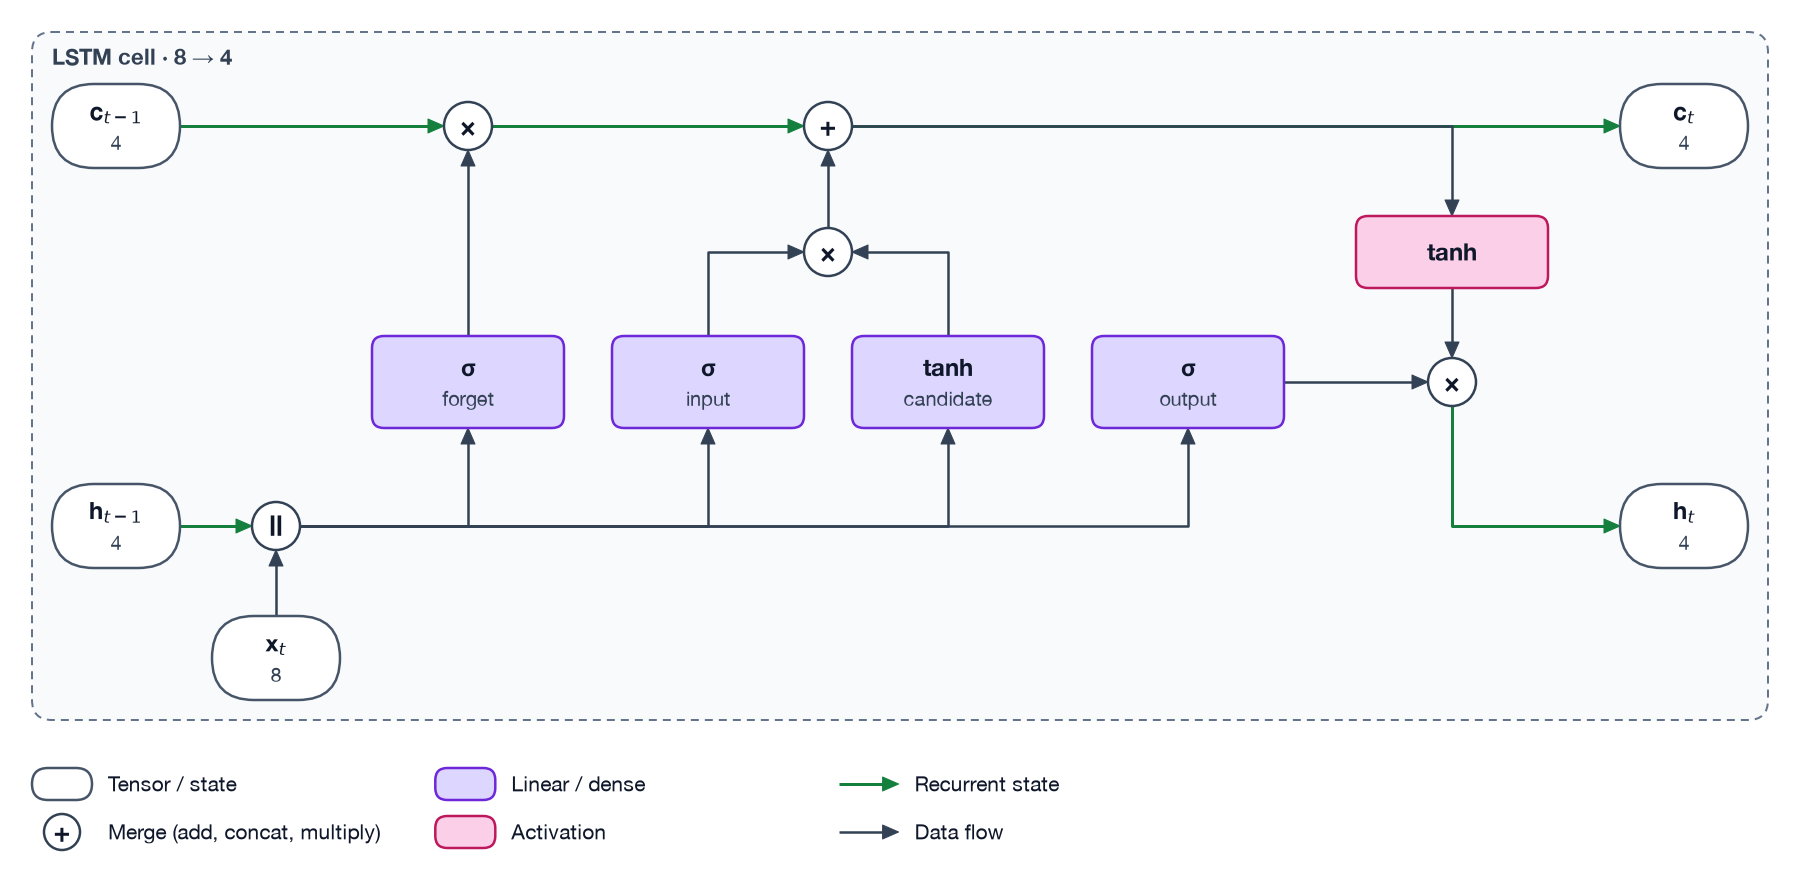

In [7]:
tg.draw(LSTMNet(), torch.randn(1, 10, 8), view="cell")

**The same:** the cell state carried from step to step (c<sub>t−1</sub> → c<sub>t</sub>, the carousel), the input gate (σ) scaling the new input (tanh, *candidate*), and the output gate (σ) scaling the squashed state on its way out.

**Tensorgami adds:** that h<sub>t−1</sub> and x<sub>t</sub> are concatenated (‖) before every gate.

**Different:** PyTorch's LSTM is the one used today, with the *forget* gate that Gers, Schmidhuber and Cummins added in 2000 to scale the carousel; the 1997 cell has no forget gate, its self-connection is fixed at 1.0. The paper draws one cell's units and weights (net<sub>c</sub>, w<sub>c</sub>); Tensorgami draws the gates as operations on vectors, 4 cells at once here.

## 6. U-Net · Ronneberger, Fischer & Brox (2015) · 152,520 citations

[arXiv:1505.04597](https://arxiv.org/abs/1505.04597), Fig. 1: the U-Net architecture.

<img src="https://ar5iv.labs.arxiv.org/html/1505.04597/assets/u-net-illustration-correct-scale2.svg" alt="U-Net, Fig. 1" width="620">

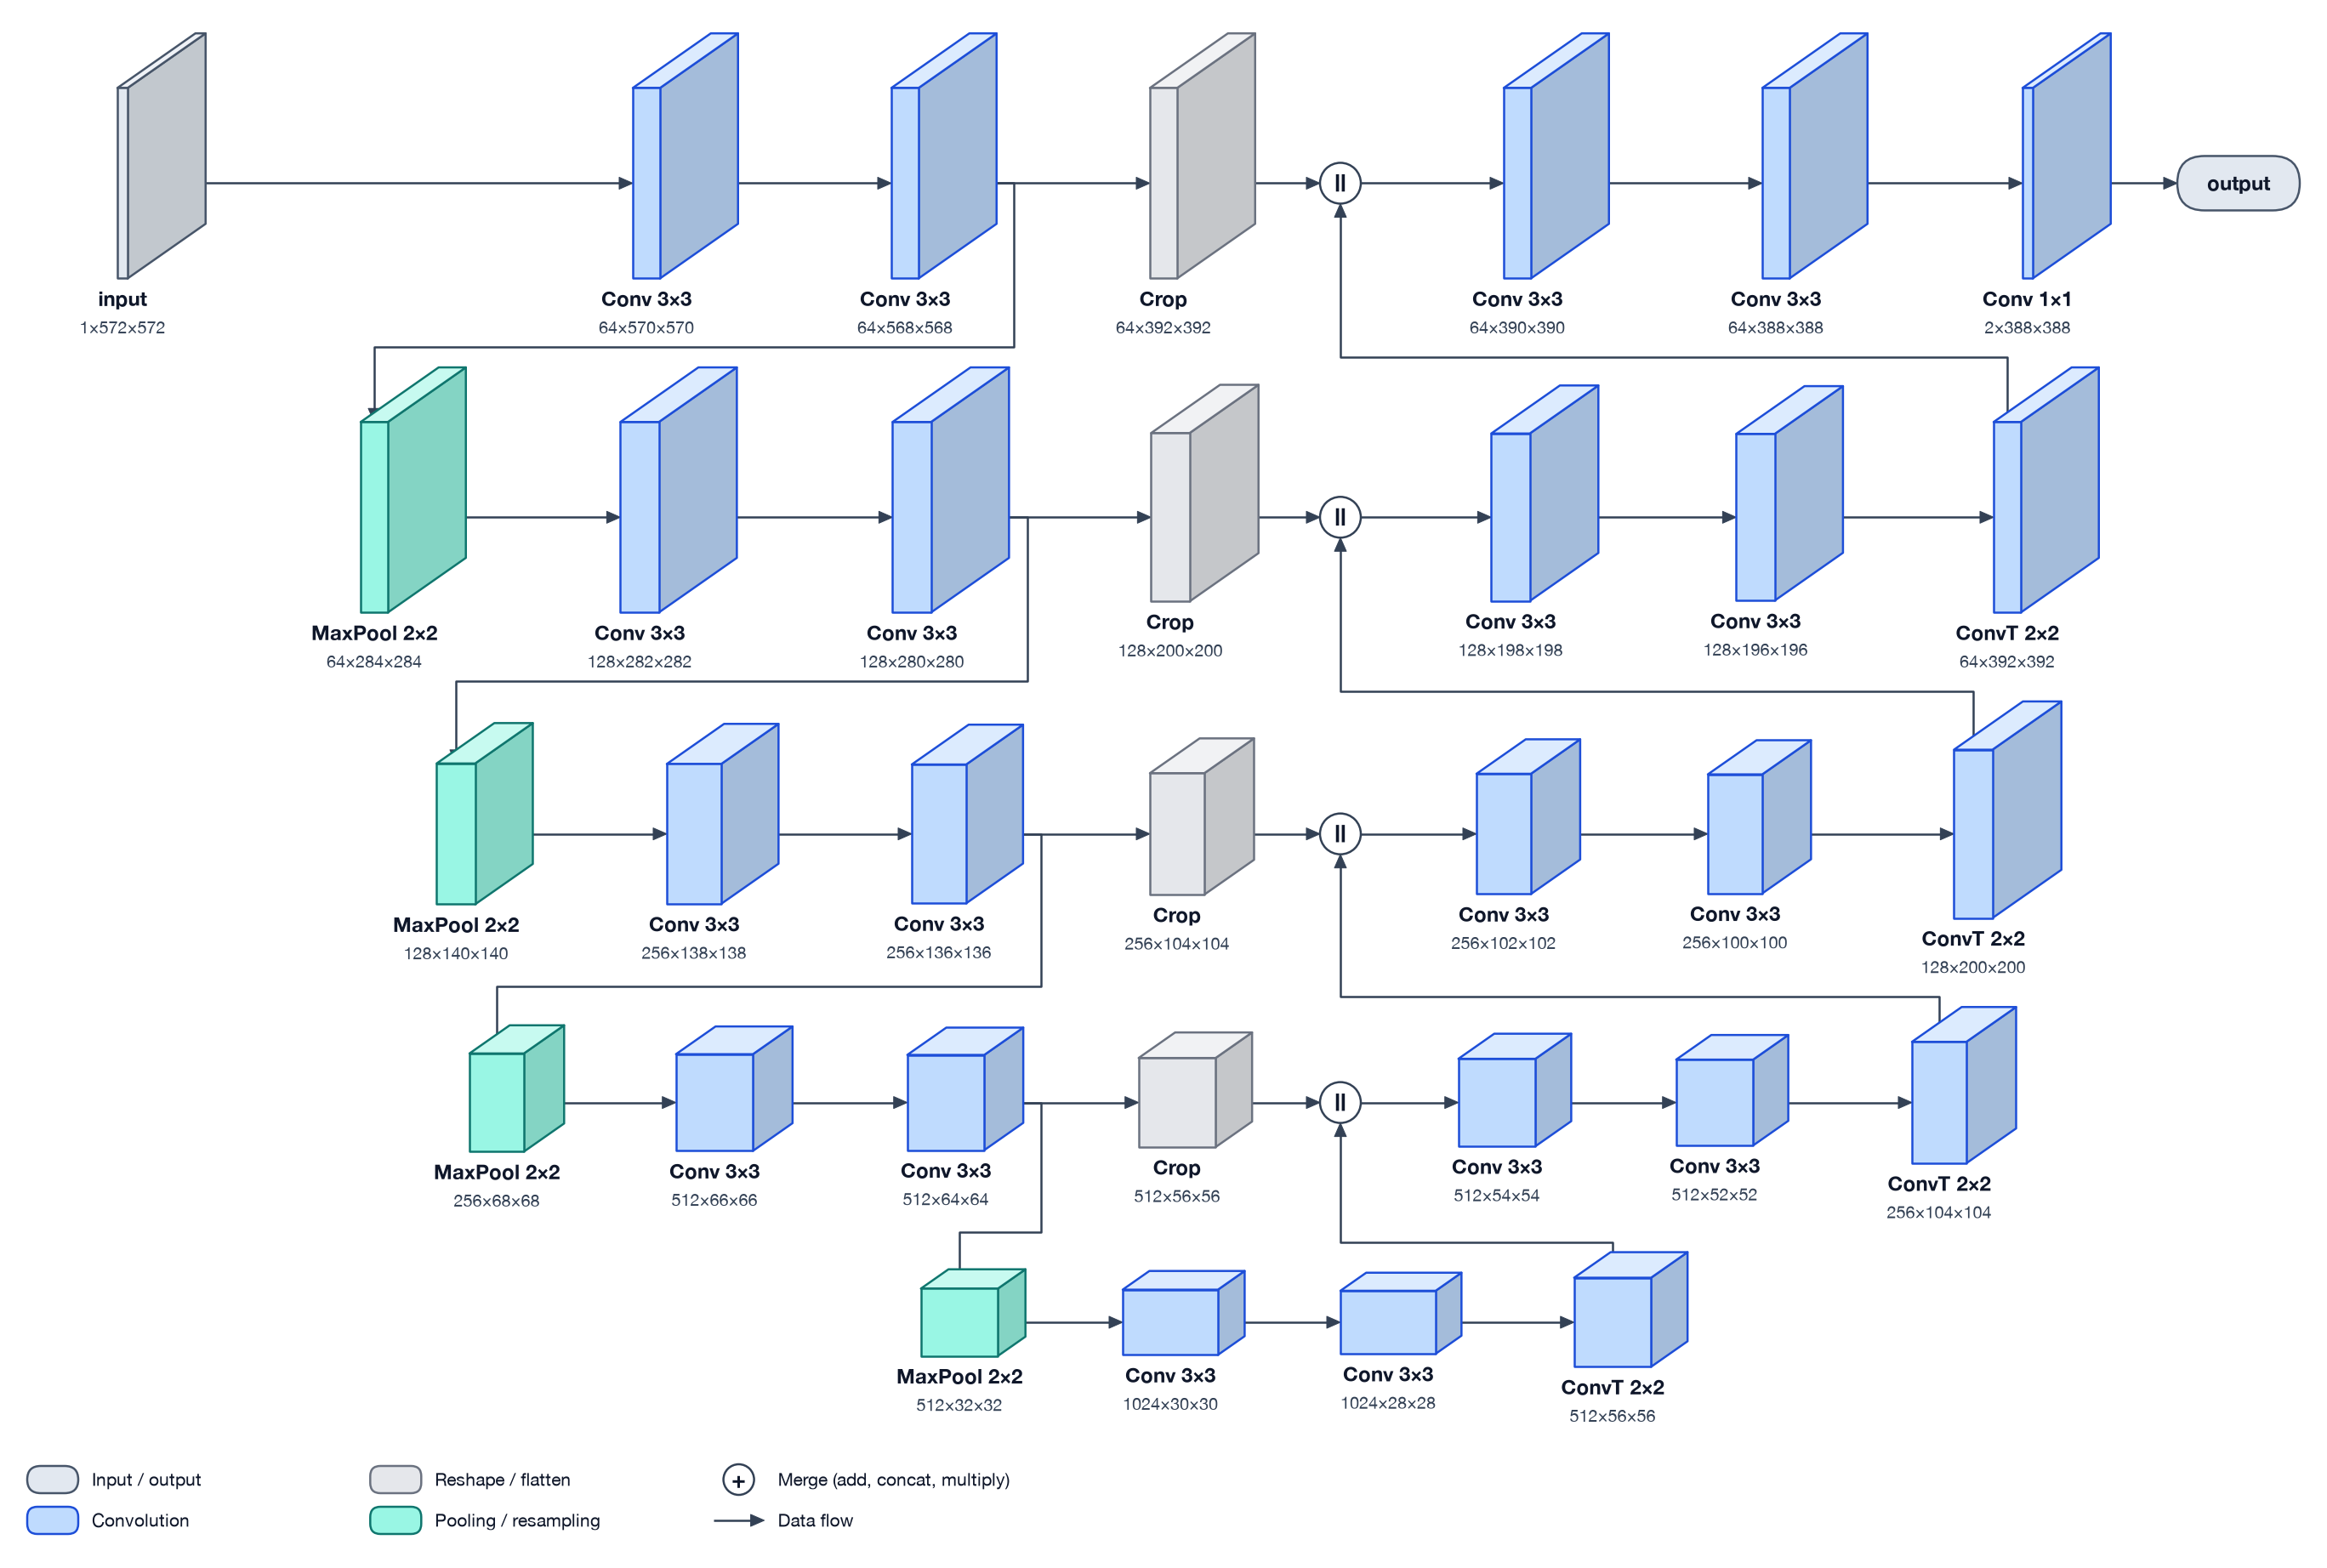

In [8]:
tg.draw(meta(UNet), torch.randn(1, 1, 572, 572), view="volume")

**The same:** the U itself: a 572 × 572 tile down four levels (two unpadded 3×3 convolutions, then 2×2 max pooling), the 1024-channel bottom, four levels up (2×2 up-convolution, concatenation with the cropped skip, two convolutions), and the 1×1 convolution to a 388 × 388 map of 2 classes. Every feature map has its size, as in the paper (570, 568, … 388), and so does every crop (568 → 392).

**Different:** the paper uses one colour and explains its arrows in a legend (conv 3×3 ReLU, copy and crop, max pool, up-conv); Tensorgami draws each operation as its own volume, coloured by kind. The paper draws a concatenation as a half-white box, here it is ‖ joining the two tensors.

**Changed in Tensorgami by this comparison:** its first convolutions and the 1×1 output layer used to sit outside the U, on lines of their own, and the crops were dropped (a 568 × 568 map seemed to join a 392 × 392 one). Now the whole encoder–decoder is folded, and a crop stays in the drawing.

## 7. Faster R-CNN · Ren, He, Girshick & Sun (2015) · 111,801 citations

[arXiv:1506.01497](https://arxiv.org/abs/1506.01497), Fig. 2: Faster R-CNN, a single unified network.

<img src="https://ar5iv.labs.arxiv.org/html/1506.01497/assets/model.png" alt="Faster R-CNN, Fig. 2" width="380">

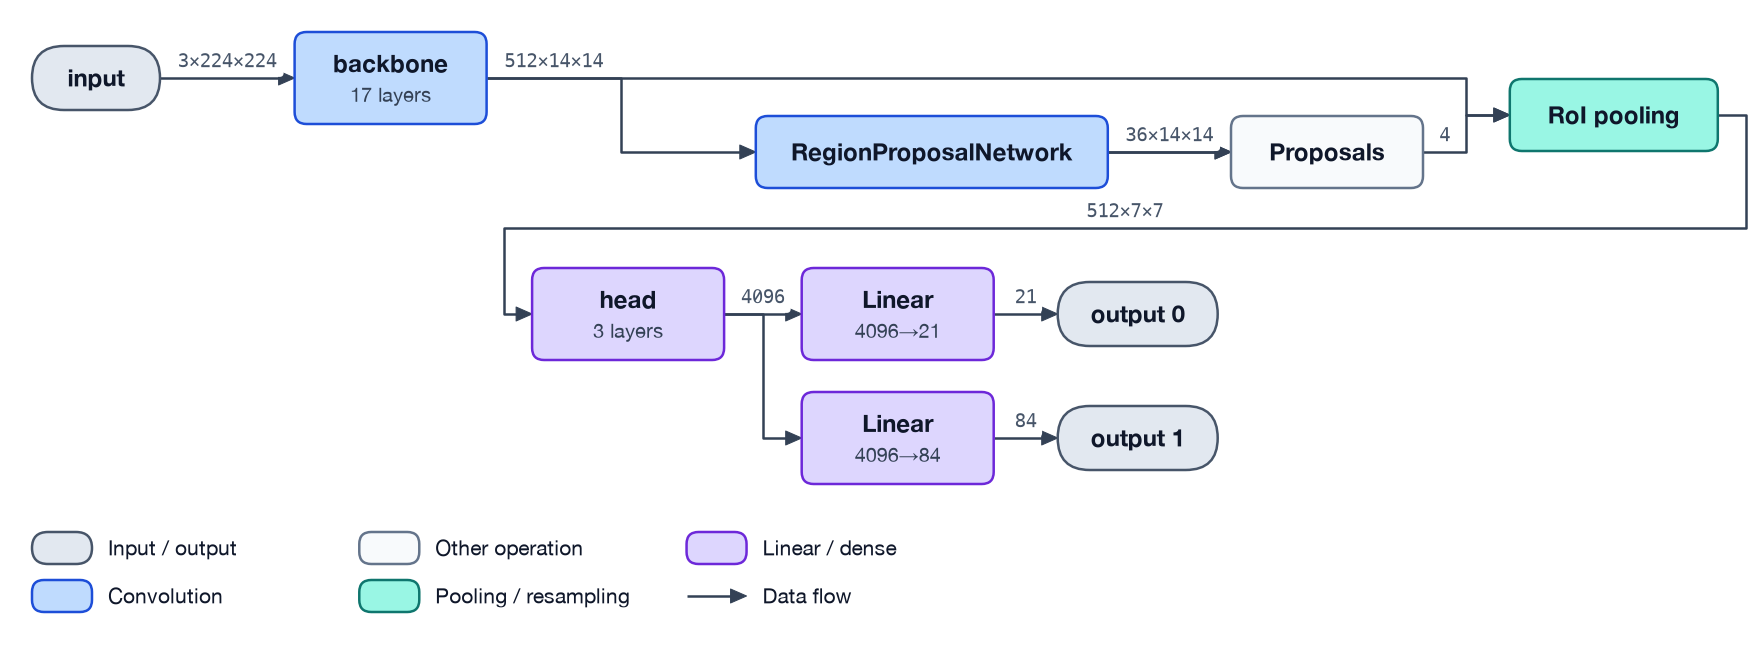

In [9]:
tg.draw(FasterRCNN(), torch.randn(1, 3, 224, 224), level="stages", overrides=FASTER_RCNN_OVERRIDES)

**The same:** the shared convolutional layers (VGG-16's 13), whose feature maps go two ways: into the region proposal network, whose proposals pick the regions, and straight into RoI pooling; then the classifier, two dense layers and the class scores and box regressions (21 PASCAL VOC classes).

**Tensorgami adds:** the proposal network's outputs, objectness scores and box offsets for k = 9 anchors at every position of the 14 × 14 map, and every shape.

**Different:** the paper's figure is an illustration (the photograph, feature maps as planes, proposal boxes); Tensorgami draws the computation. Picking proposals and RoI pooling are not layers: each is one box here (`overrides` draws a module as one box), and the model keeps 8 proposals without the paper's non-maximum suppression. Once the model runs, the proposals are data: this model is traced on real tensors, not on the meta device.

## 8. Vision Transformer · Dosovitskiy et al. (2021) · 110,951 citations

[arXiv:2010.11929](https://arxiv.org/abs/2010.11929), Fig. 1: model overview.

<img src="https://ar5iv.labs.arxiv.org/html/2010.11929/assets/model_scheme.png" alt="ViT, Fig. 1" width="720">

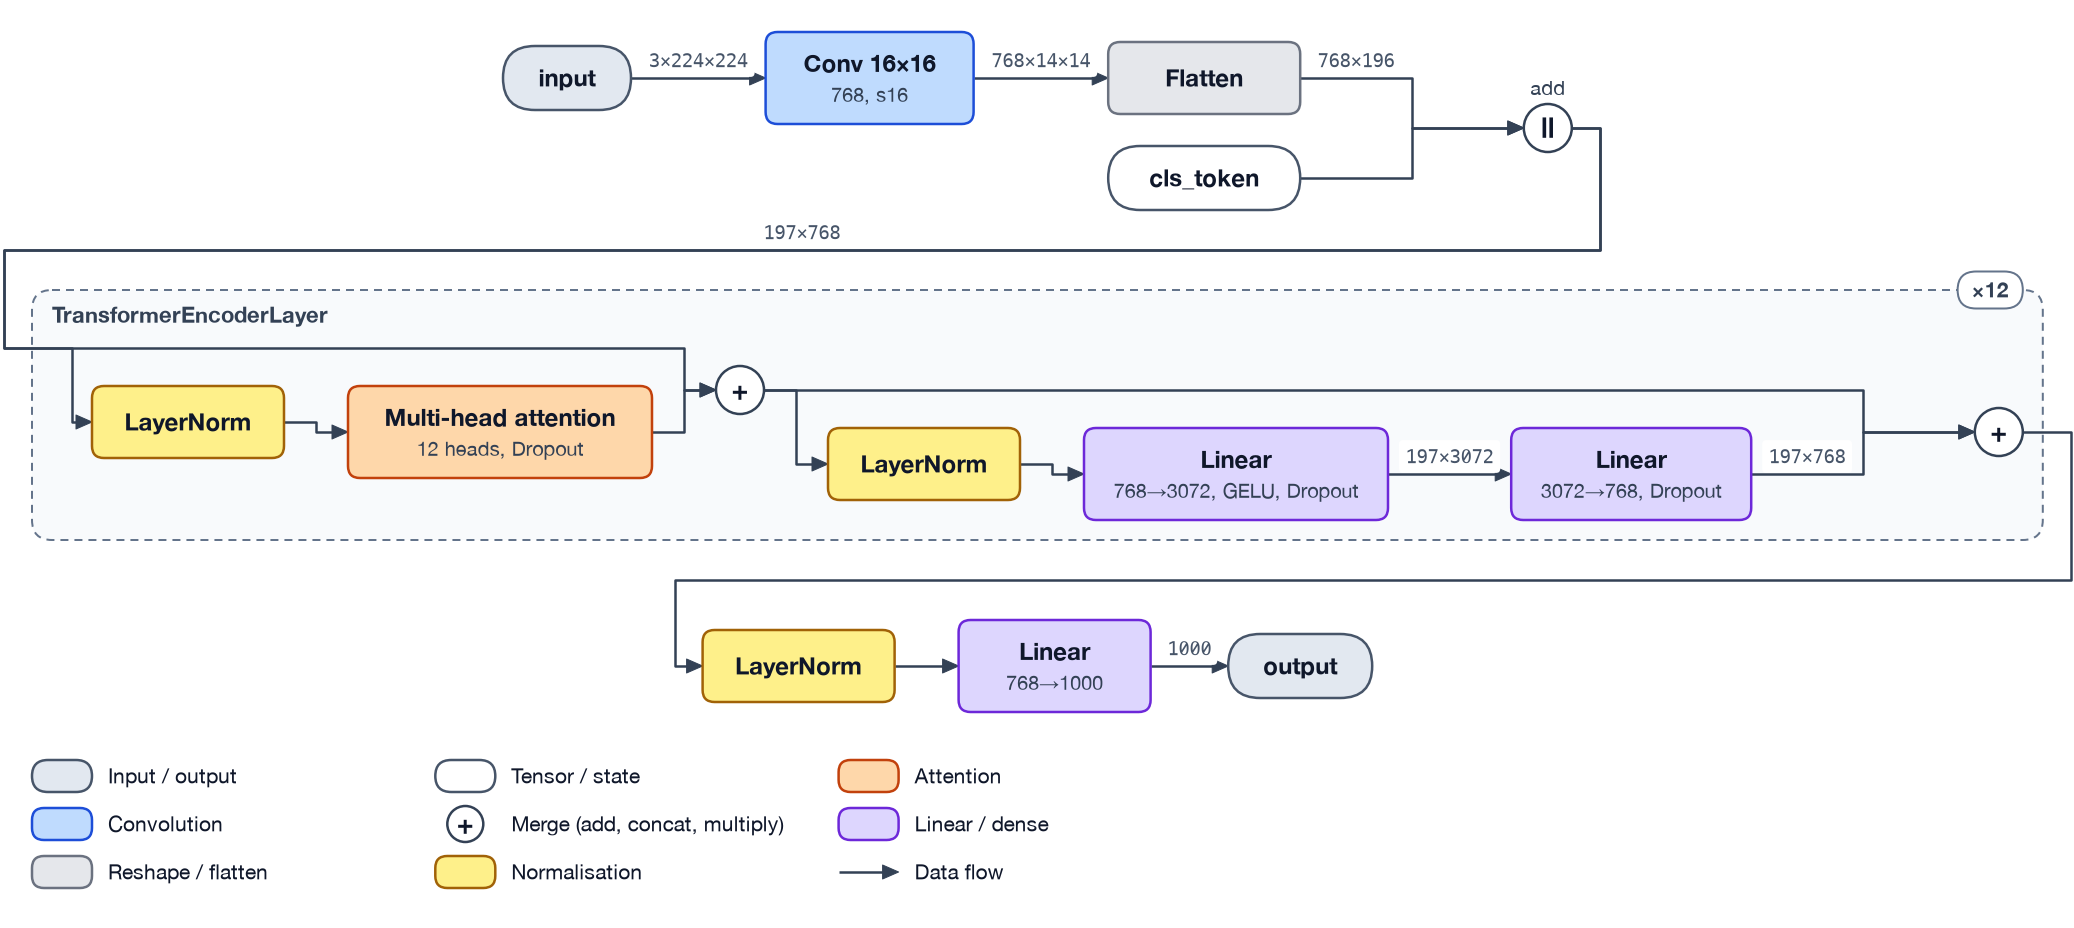

In [10]:
tg.draw(meta(VisionTransformer), torch.randn(1, 3, 224, 224))

**The same:** the 16 × 16 patches linearly projected (a 16 × 16 convolution with stride 16 is that projection, then flattened to 196 tokens of 768), the learnable [class] token (`cls_token`) joined to them, the position embeddings added (the `add` on the ‖), and the figure's right half exactly: L = 12 encoder layers, each Norm → Multi-Head Attention → ⊕ → Norm → MLP → ⊕; then the MLP head.

**Tensorgami adds:** the LayerNorm before the head (in the paper's equations, not its figure) and the shapes (197 × 768).

**Different:** the paper shows the image cut into patches and a column per token; here the tokens are a dimension of the tensors. Taking the class token's output for the head is folded into the wire.

## 9. LeNet-5 · LeCun, Bottou, Bengio & Haffner (1998) · 91,030 citations

Not on arXiv: see [Fig. 2 on page 7 of the paper (PDF)](http://yann.lecun.com/exdb/publis/pdf/lecun-01a.pdf#page=7), the architecture of LeNet-5 with each feature map as a plane.

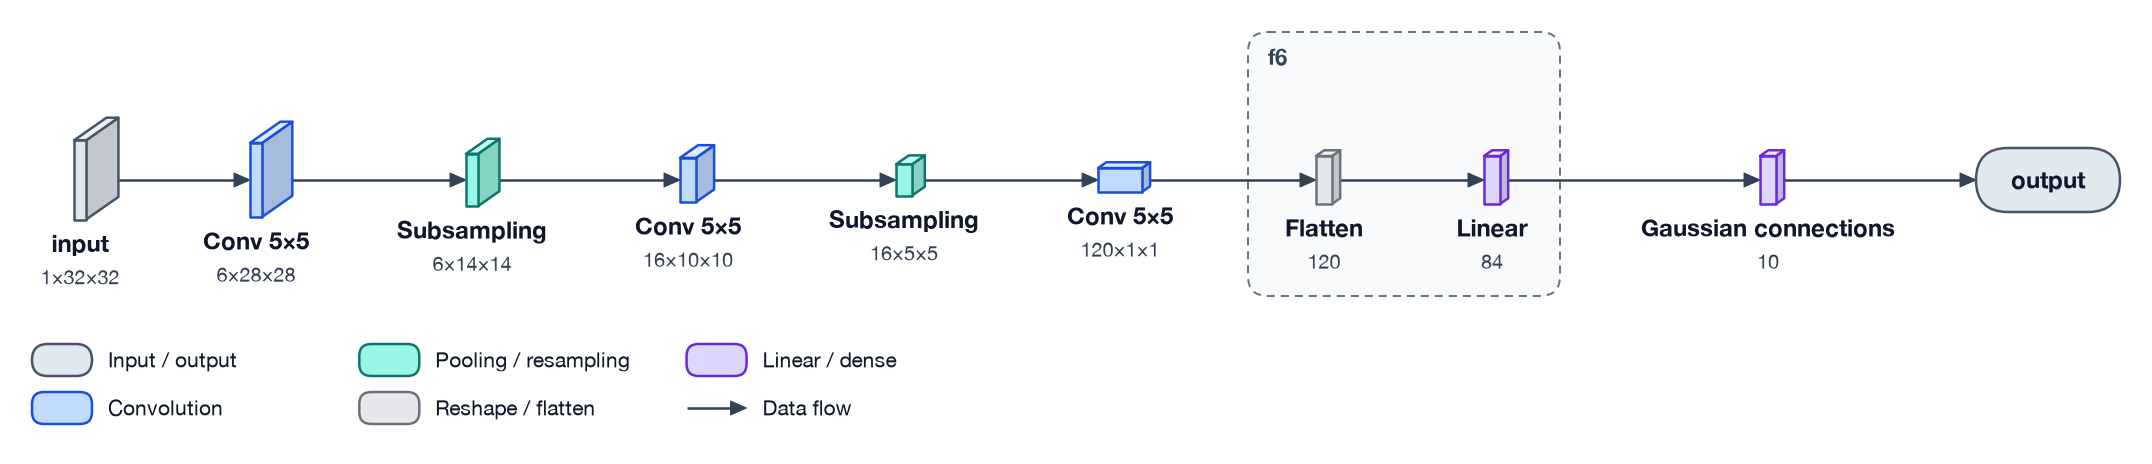

In [11]:
tg.draw(LeNet5(), torch.randn(1, 1, 32, 32), view="volume", overrides=LENET_OVERRIDES)

**The same:** INPUT 32 × 32 → C1 6@28 × 28 → S2 6@14 × 14 → C3 16@10 × 10 → S4 16@5 × 5 → C5 120 → F6 84 → OUTPUT 10, with the paper's own names for the subsampling layers and the Gaussian connections (`overrides` names the two custom modules).

**Different:** the paper draws every feature map as a separate plane, stacked; Tensorgami draws each layer's output as one volume. C3 is connected to all of S2's maps here; the paper's sparse connection table (its Table I) is not modelled.

## 10. YOLO · Redmon, Divvala, Girshick & Farhadi (2016) · 84,269 citations

[arXiv:1506.02640](https://arxiv.org/abs/1506.02640), Fig. 3: the architecture.

<img src="https://ar5iv.labs.arxiv.org/html/1506.02640/assets/net.svg" alt="YOLO, Fig. 3" width="820">

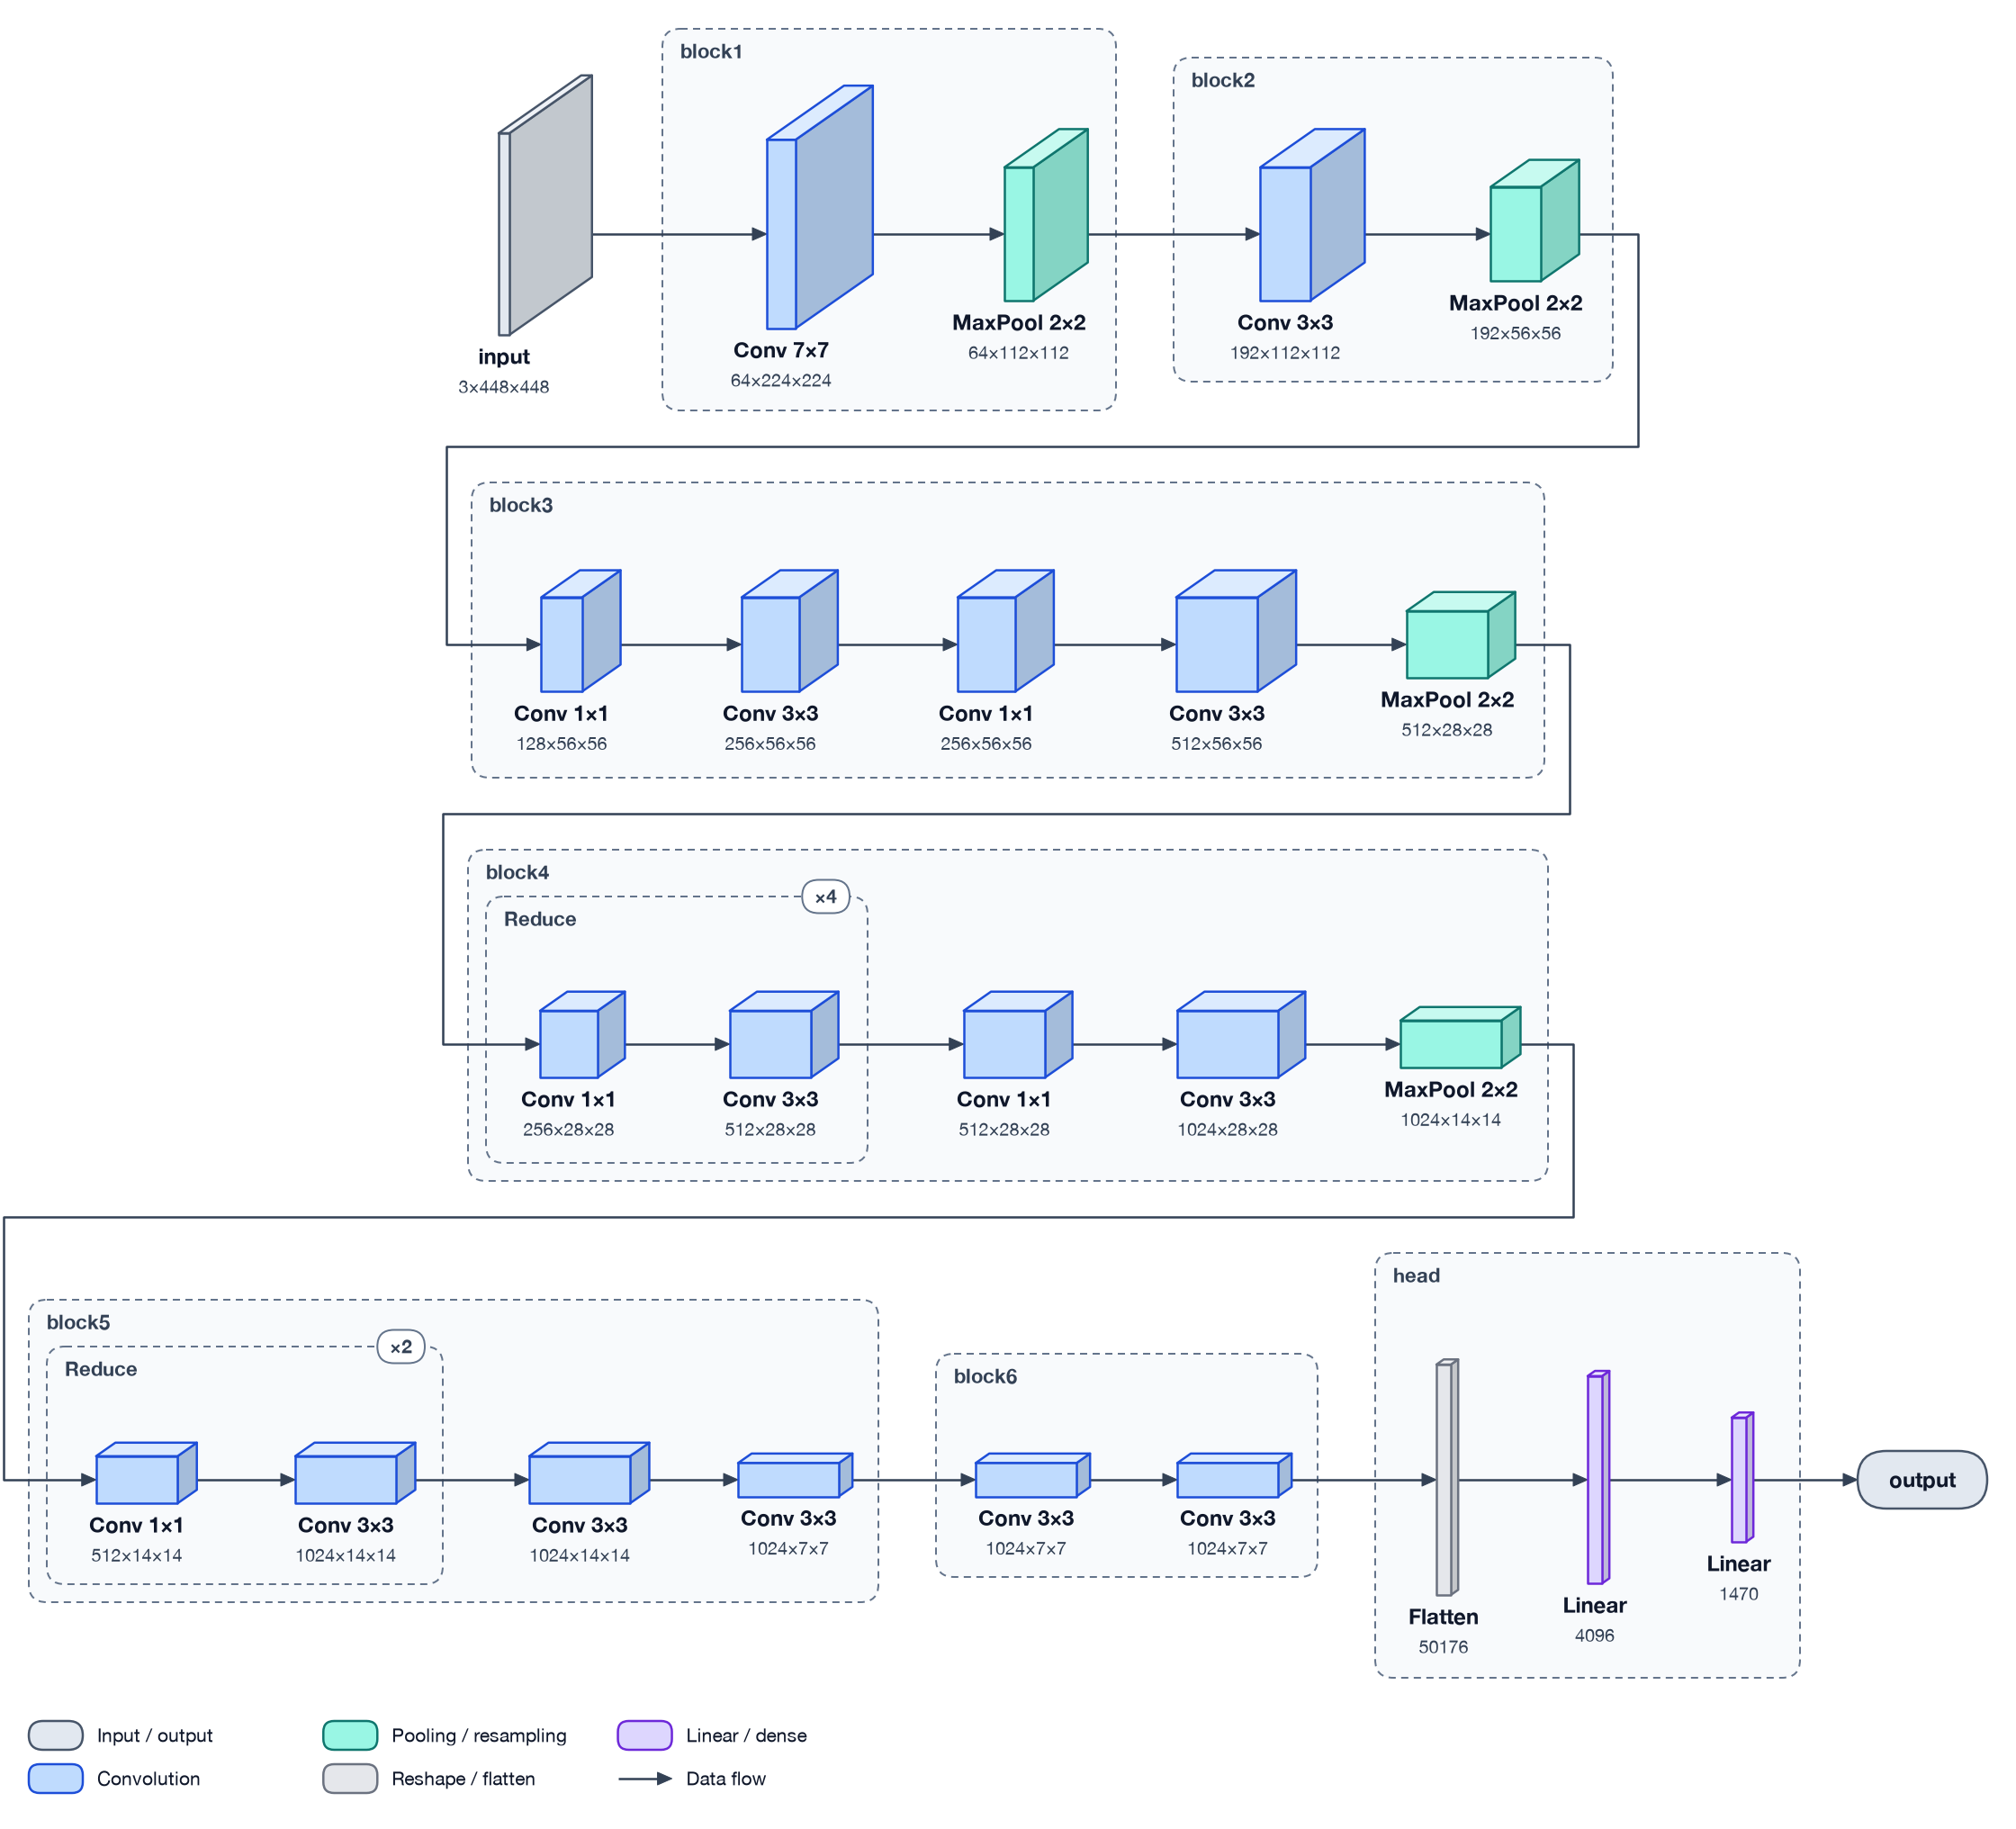

In [12]:
tg.draw(meta(YOLO), torch.randn(1, 3, 448, 448), view="volume")

**The same:** the 448 × 448 input, the 24 convolutional layers in the paper's six columns (the frames `block1` … `block6`), the repeated 1×1 / 3×3 pairs drawn once and marked ×4 and ×2 where the paper writes "}×4", and the two dense layers ending in the 7 × 7 × 30 grid of predictions (1470 values).

**Different:** the paper draws one volume per column, with that column's layers written below it (7×7×64-s-2, Maxpool 2×2-s-2); Tensorgami draws every layer as a volume with its output size. The paper's kernel windows are not drawn.

## What the comparison shows

| | The structure | What the paper's figure adds | What Tensorgami adds |
|---|---|---|---|
| ResNet | ✓ | every layer drawn (depth on show) | batch norm, shapes, ×N for repeats |
| Transformer | ✓ | the *masked* label | inside of Add & Norm and Feed Forward, shapes |
| AlexNet | ✓ | the two-GPU split, kernel windows | — (the same volumes) |
| BERT | ✓ | a column per token, fine-tuning | the encoder layer's contents |
| LSTM | ✓ (modern cell) | units and weights of one cell | the ‖ of h and x before the gates |
| U-Net | ✓ | one colour and a legend of arrows | an operation per volume, coloured by kind |
| Faster R-CNN | ✓ | the photograph, proposal boxes | the RPN's outputs, shapes |
| ViT | ✓ | patches of the image, a column per token | the final LayerNorm, shapes |
| LeNet-5 | ✓ | every feature map as a plane | — (the same sequence) |
| YOLO | ✓ | layer specifications under each column | every layer as a volume, ×4 and ×2 |

Every model's structure comes out as its paper draws it, from one call on the PyTorch model, with exact shapes throughout. The papers' figures add what is not in the computation: illustrations of the data (photographs, patches, a column per token), how the work was spread over hardware (AlexNet's two GPUs), and, in ResNet's case, every layer on purpose, to show the depth.

**Changed in Tensorgami by this comparison**

- An encoder–decoder with nested skips is folded whole: the layers before the outermost skip and after its merge join the U's top row (U-Net's first convolutions and its 1×1 output layer were drawn outside the U).
- A crop stays in the drawing (U-Net's *copy and crop*): before, every indexing operation was dropped at the layer level, so a 568 × 568 map seemed to join a 392 × 392 one.
- A module fed partway along by another module (the Transformer's decoder, fed the encoder's output at its second attention) stands beside it, both starting level, the wire entering from the side; before, the decoder came after the whole encoder.
- Every figure is more compact: less space between layers, rows and frames (about a fifth less area on average).
- A tall top → bottom figure stands in columns side by side (ResNet-34: four columns instead of one), and a short last row is centred under the long one (AlexNet's classifier), the wire coming back to the middle.

**Ideas it suggests (not done yet)**

- Leave out operations whose result reaches no output: PyTorch's `TransformerDecoder` compares the mask with a causal one inside its forward pass (`triu`, `eq`, `all`), which showed up as boxes; the model here passes `tgt_is_causal=True` to avoid it.
- An option to draw repeated blocks unfolded, for figures meant to show depth (ResNet's 34 layers).
- Grouped convolutions in a layer's details (AlexNet's two GPUs), and *masked* on attention with a causal mask.